---
# Nicht-lineare Klassifikation mittels SVM mit RBF-Kernel


---
# Vorbereitung - Dependencies

In [1]:
# (1) Mathe / Data Science
import numpy as np
import pandas as pd

# (2) scikit-learn: SVM
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# (3) Visualisierung
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from helpers import scatter_classes, plot_svm, legend_handles, GREY, LIGHT_GREY, BLACK, COLOR_C_1, COLOR_C_2, BG_CMAP

# Darstellung der Plots innerhalb des Notebooks
%matplotlib inline

## Daten

In [2]:
# (1) Laden der Daten
nl = pd.read_csv("data/nonlinear_data.csv")
X_nl = nl[["x1", "x2"]].to_numpy()
y_nl = nl["label"].to_numpy()

# (2) Debugging
print("class counts:", nl["label"].value_counts().to_dict())


class counts: {1: 150, -1: 150}


## Wiederholung: Training der linearen SVM

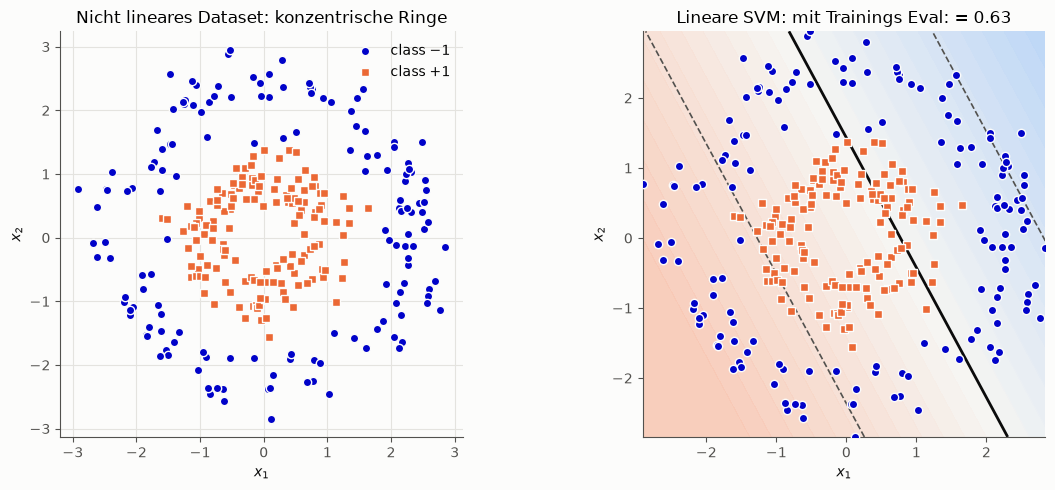

In [3]:
# (1) Training der linearen SVM
lin_try = SVC(kernel="linear", C=1).fit(X_nl, y_nl)

# (2) Plots
# Zwei Plots: die Rohdaten (links) und die fehlschlagende lineare SVM (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
scatter_classes(ax1, X_nl, y_nl)
ax1.set_title("Nicht lineares Dataset: konzentrische Ringe"); ax1.legend(loc="upper right"); ax1.set_aspect("equal")

plot_svm(ax2, lin_try, X_nl, y_nl, f"Lineare SVM: mit Trainings Eval: = {lin_try.score(X_nl, y_nl):.2f}", show_sv=False)
ax2.set_aspect("equal")

plt.tight_layout()
plt.show()

Die lineare SVM kann die Klassen nur minimal separieren (63% ist immerhin besser als Wuerfeln): die Klassen sind aber in jedem Fall **nicht linear trennbar** in $(x_1, x_2)$.

## Training einer SVM mit RBF-Kernel

train accuracy: 0.981
test  accuracy: 0.978
support vectors: 37 of 210 training points


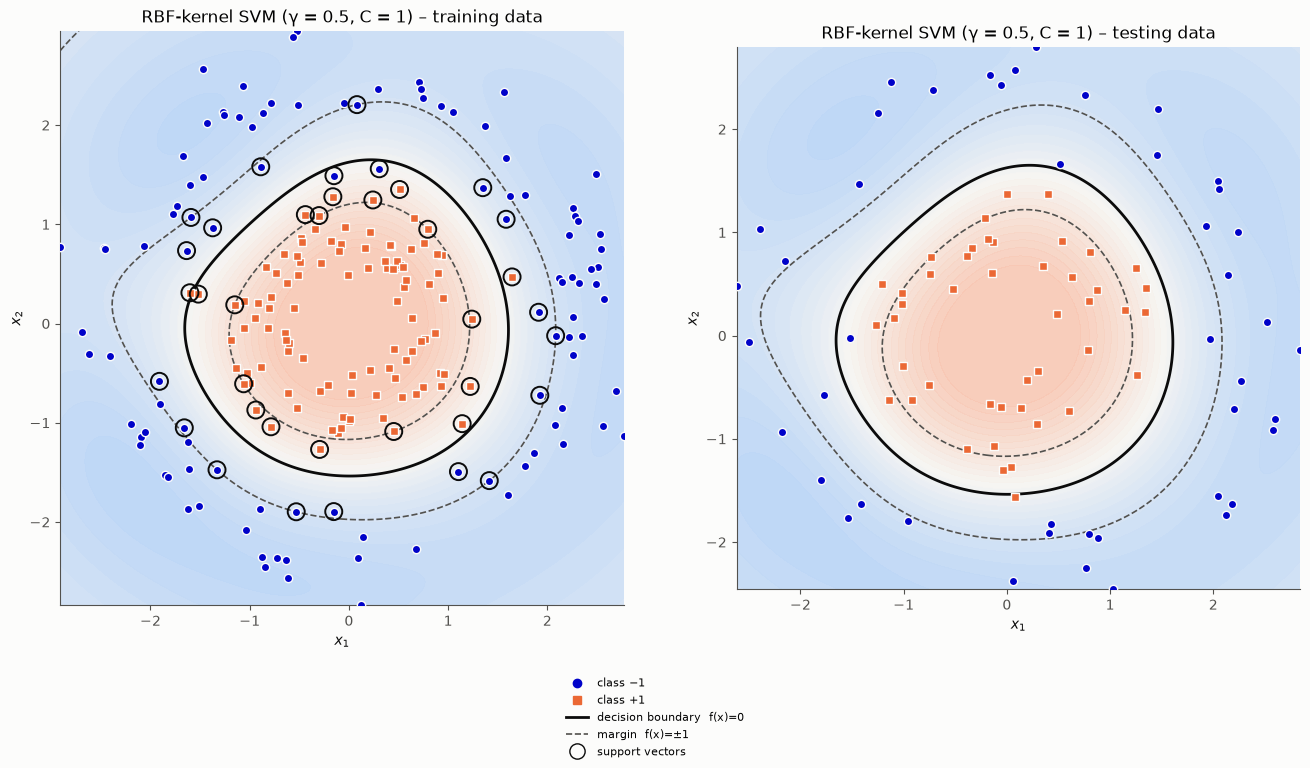

In [4]:
# (1) Train / Testset Generierung
#     stratify: splitte gleichmaessig ueber alle Klassen, nicht nur ueber alle Daten
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(X_nl, y_nl, test_size=0.3, stratify=y_nl, random_state=0)

# (2) RBF-SVM mit gamma = 0.5 (Kernelbreite) und 
#     C = 1 (Strafparameter fuer Margin-Verletzungen) trainieren
rbf = SVC(kernel="rbf", gamma=0.5, C=1).fit(Xn_tr, yn_tr)

# (3) Debugging
print(f"train accuracy: {rbf.score(Xn_tr, yn_tr):.3f}")
print(f"test  accuracy: {rbf.score(Xn_te, yn_te):.3f}")
print(f"support vectors: {len(rbf.support_)} of {len(yn_tr)} training points")

# (4) Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 9))
axes[0].set_aspect("equal")
axes[1].set_aspect("equal")
plot_svm(axes[0], rbf, Xn_tr, yn_tr, "RBF-kernel SVM (γ = 0.5, C = 1) – training data")
plot_svm(axes[1], rbf, Xn_te, yn_te, "RBF-kernel SVM (γ = 0.5, C = 1) – testing data", show_sv=False)
fig.legend(handles=legend_handles(), loc="lower center", fontsize=8)

plt.show()

## Die Parameter $\gamma$ und $C$

Die RBF-SVM hat zwei Hyperparameter:

- $\gamma$ – Kernel Breite 
- $C$ – Gewichtung der Strafe bei Margin - Verletzung

Beide beeinflussen den **bias–variance trade-off**:

| | kleiner Wert | grosser Wert |
|---|---|---|
| $\gamma$ | weiche, nahezu lineare Grenze → **underfitting** | Grenze um einzelne Punkte herum → **overfitting** |
| $C$ | breiter soft margin, mehr Fehlertoleranz | starke Approximation der Trainingsdaten |

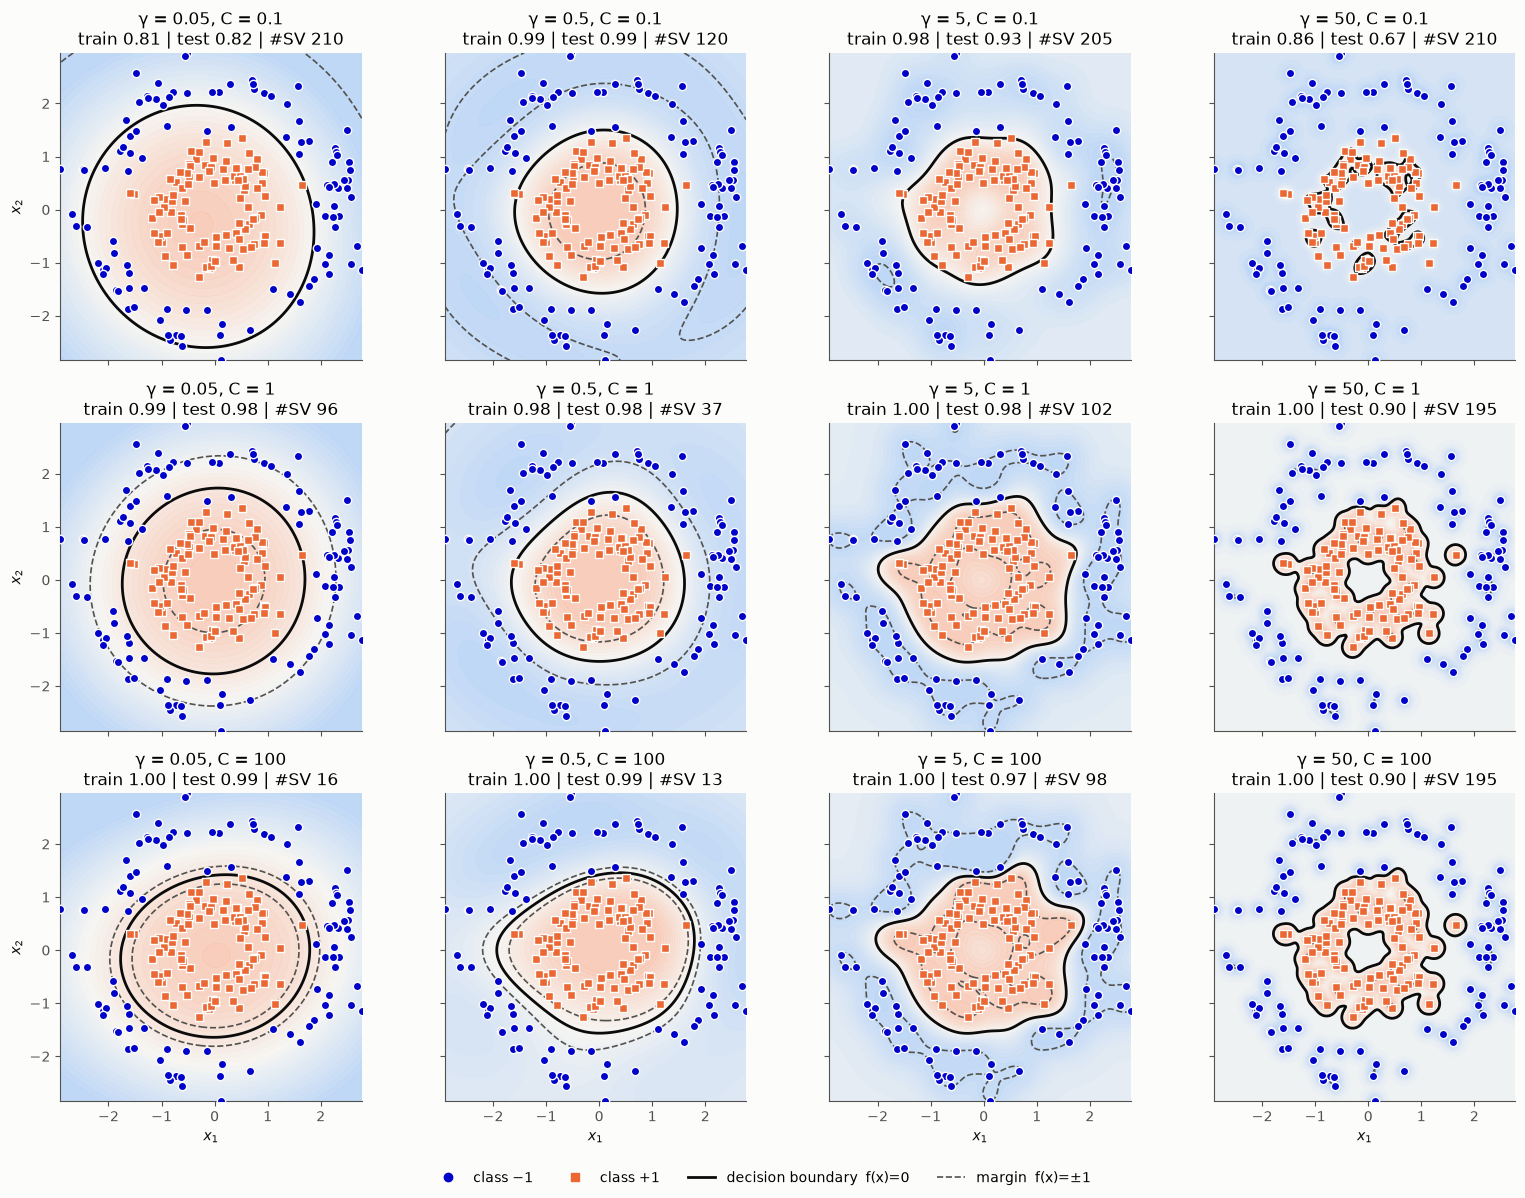

In [5]:
# (1) Parameter fuer 
#     gamma (Spalten des Gitters) und 
#     C     (Zeilen des Gitters) 
#     zum Vergleich
gammas = [0.05, 0.5, 5, 50]
Cs = [0.1, 1, 100]

# (2) Plots fuer C (pro Zeile) und gamma (pro Spalte)
#     Fuer jede Kombination trainieren wir eine SVM!
fig, axes = plt.subplots(len(Cs), len(gammas), figsize=(16, 12), sharex=True, sharey=True)
for i, C in enumerate(Cs):
    for j, gamma in enumerate(gammas):
        # RBF-SVM mit diesem gamma und C auf den Trainingsdaten trainieren
        mdl = SVC(kernel="rbf", gamma=gamma, C=C).fit(Xn_tr, yn_tr)

        plot_svm(axes[i, j], mdl, Xn_tr, yn_tr, show_sv=False, res=200,
                 title=f"γ = {gamma}, C = {C}\ntrain {mdl.score(Xn_tr, yn_tr):.2f} | test {mdl.score(Xn_te, yn_te):.2f} | #SV {len(mdl.support_)}")
        axes[i, j].set_aspect("equal")

        # y-Beschriftung nur in der ersten Spalte und 
        # x-Beschriftung nur in der untersten Zeile behalten
        if j: axes[i, j].set_ylabel("")
        if i < len(Cs) - 1: axes[i, j].set_xlabel("")

# (3) Formatierung
fig.legend(handles=legend_handles(False), loc="lower center", ncol=4)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

## UEBUNG: Cross-Validierung, um $\gamma$ und $C$ zu bestimmen

Die Standardmethode zur Hyperparameter Bestimmung ist **grid search with k-fold cross-validation** auf den Trainingsdaten; Das Testset verwenden wir nur zur Evaluierung am Ende. 

Eine Normalisierung der Features ist bei uns nicht noetig, empfielt sich aber immer!

Beste Parameter: {'C': 100.0, 'gamma': 0.316}
Beste Cross Validation Trainings - Accuracy: 1.000
Test Accuracy   : 0.978


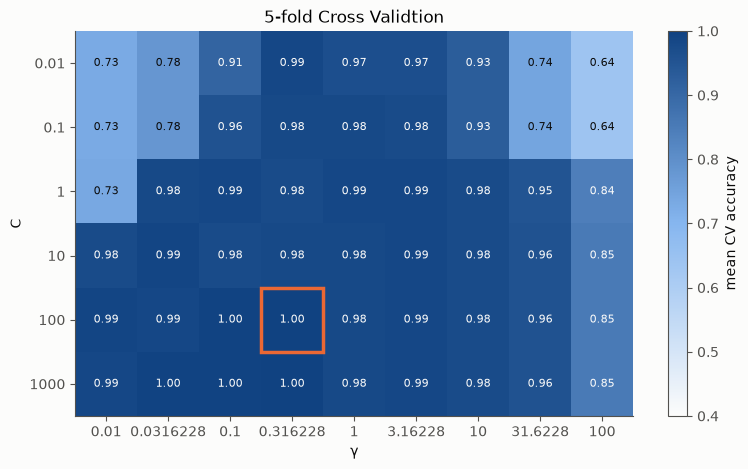

In [6]:
# (1) Parametrisierung fuer die Grid Search
# Hyperparameter-Raster: 6 Werte fuer C und 9 Werte fuer gamma, beide logarithmisch verteilt (10^-2 ... 10^3 bzw. 10^-2 ... 10^2)
param_grid = {"C": np.logspace(-2, 3, 6), "gamma": np.logspace(-2, 2, 9)}
# Grid Search: probiert jedes (C, gamma) Paar mit 5-facher stratifizierter Kreuzvalidierung, nur auf den Trainingsdaten
search = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=0))

# (2) Ausfuehrung der Grid Search
# Suche ausfuehren (trainiert 6 x 9 x 5 Modelle)
search.fit(Xn_tr, yn_tr)

# (3) Debugging
# Beste Hyperparameter-Kombination aus der Kreuzvalidierung
print("Beste Parameter:", {k: round(float(v), 3) for k, v in search.best_params_.items()})
# Mittlere Kreuzvalidierungs-Genauigkeit der besten Kombination
print(f"Beste Cross Validation Trainings - Accuracy: {search.best_score_:.3f}")
# Genauigkeit des besten Modells auf dem Testset
print(f"Test Accuracy   : {search.score(Xn_te, yn_te):.3f}")

# (4) Plot aller Grid Search Ergebnisse
# (4.1) Heatmap
# Die flache Liste der mittleren CV-Werte in eine (C x gamma) Tabelle fuer die Heatmap umformen
scores = search.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
# Heatmap-Abbildung
fig, ax = plt.subplots(figsize=(9, 5))
# Die Werte als Farben zeichnen; die festen vmin/vmax halten die Farbskala vergleichbar
im = ax.imshow(scores, cmap=LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#86b6ef", "#104281"]),
               vmin=0.4, vmax=1, aspect="auto")

# (4.2) Beschriftung
# Spalten mit gamma-Werten und Zeilen mit C-Werten beschriften
ax.set_xticks(range(len(param_grid["gamma"])), [f"{g:g}" for g in param_grid["gamma"]])
ax.set_yticks(range(len(param_grid["C"])), [f"{c:g}" for c in param_grid["C"]])
ax.set_xlabel("γ"); ax.set_ylabel("C"); ax.grid(False)
# Den Wert in jede Zelle schreiben; bei dunklen Zellen weisser Text fuer bessere Lesbarkeit
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        ax.text(j, i, f"{scores[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="#fcfcfb" if scores[i, j] > 0.8 else BLACK)

# (4.3) Kennzeichnung des besten Ergebnisses
# Zeilen- und Spaltenindex der besten (C, gamma) Kombination bestimmen
bi = list(param_grid["C"]).index(search.best_params_["C"])
bj = list(param_grid["gamma"]).index(search.best_params_["gamma"])
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, ec=COLOR_C_2, lw=2.5))
ax.set_title("5-fold Cross Validtion")

# (4.4) Farbskala
# Farbskala mit den Scores anzeigen
fig.colorbar(im, ax=ax, label="mean CV accuracy")
plt.show()

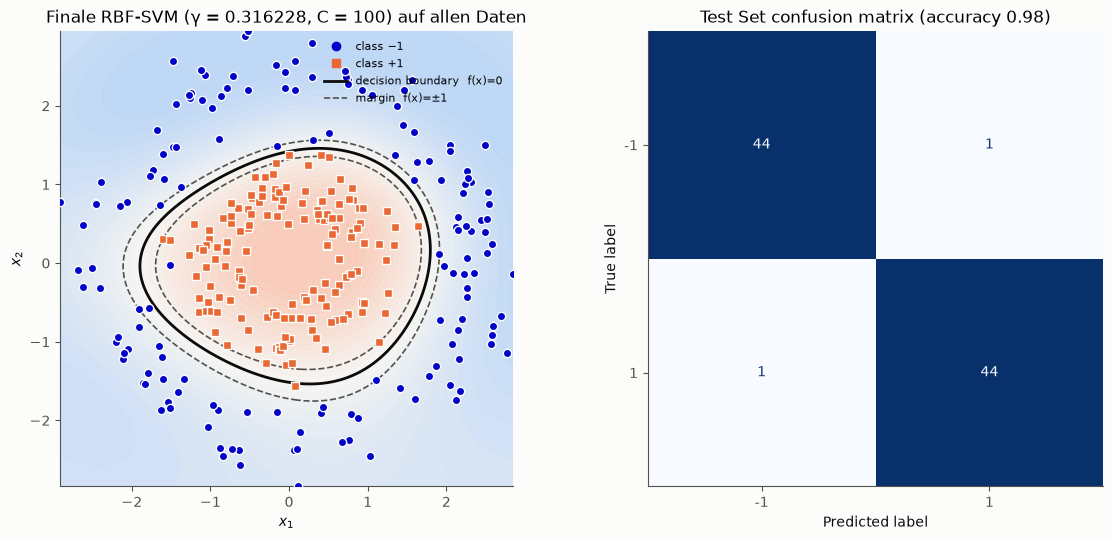

In [7]:
# (5) Visualisierung des Modells mit den besten Hyperparametern
best = search.best_estimator_

# Zwei Plots: Entscheidungsbereiche (links) und Confusion Matrix auf dem Testset (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5))

# Links: Entscheidungsbereiche des finalen Modells auf den Ringdaten; gamma und C stehen im Titel
plot_svm(ax1, best, X_nl, y_nl, f"Finale RBF-SVM (γ = {best.gamma:g}, C = {best.C:g}) auf allen Daten", show_sv=False)
ax1.legend(handles=legend_handles(False), loc="upper right", fontsize=8)
ax1.set_aspect("equal")

# Rechts: Confusion Matrix auf dem Testset (Zeilen = wahre Klasse, Spalten = vorhergesagte Klasse)
ConfusionMatrixDisplay.from_estimator(best, Xn_te, yn_te, ax=ax2, cmap="Blues", colorbar=False)
ax2.set_title(f"Test Set confusion matrix (accuracy {best.score(Xn_te, yn_te):.2f})"); ax2.grid(False)

plt.tight_layout()
plt.show()